# Day 1 — RuSentiTweet: загрузка и первичный анализ

Источник: [оригинальный репозиторий авторов датасета](https://github.com/sismetanin/rusentitweet). В проект загружен train-сплит; оставлены классы `positive`, `neutral`, `negative`, исключены служебные метки `skip` и `speech_act`. Официальный test-сплит авторов не используется: оценка делается своим стратифицированным сплитом.

Задача: мультиклассовая классификация тональности коротких русскоязычных твитов.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from classification.config import RAW_DATA_PATH
from classification.load_data import (
    class_distribution,
    dataset_info,
    length_stats_by_class,
    load_dataset,
    show_examples,
    split_data,
    text_lengths,
)

df = load_dataset(RAW_DATA_PATH)
print(RAW_DATA_PATH)

C:\Users\Aleksandra\PycharmProjects\classification\data\raw\rusentitweet.csv


## 1. Размер, типы колонок, пропуски, дубликаты

In [2]:
info = dataset_info(df)
print(f"Строк: {info['rows']}")
display(
    pd.DataFrame(
        {
            "dtype": pd.Series(info["dtypes"]),
            "missing": pd.Series(info["missing"]),
        }
    )
)
print(f"Дубликаты text: {info['duplicate_texts']}, text+label: {info['duplicate_rows']}")
print(f"Пустые text: {info['empty_texts']}")

Строк: 8842


,dtype,missing
text,str,0
label,str,0


Дубликаты text: 0, text+label: 0
Пустые text: 0


## 2. Распределение классов

,count,share
label,,
negative,2638,0.298349
neutral,4273,0.483262
positive,1931,0.218390


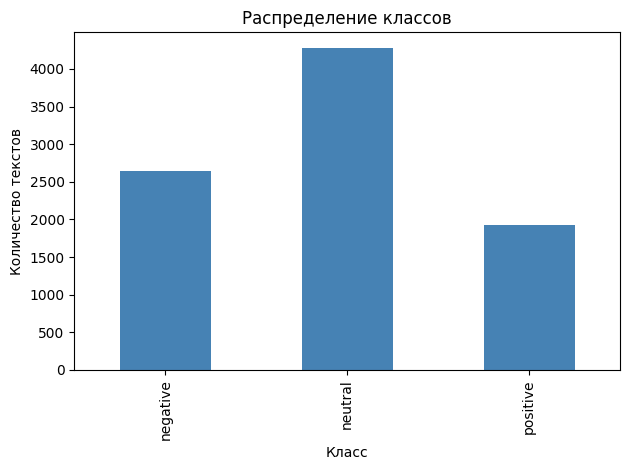

In [3]:
counts = class_distribution(df)
distribution = pd.DataFrame({"count": counts, "share": counts / counts.sum()})
display(distribution)

ax = counts.plot.bar(color="steelblue")
ax.set_title("Распределение классов")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество текстов")
plt.tight_layout()
plt.show()

## 3. Длины текстов

,count,mean,std,min,5%,25%,50%,75%,95%,max
chars,8842.0,61.53,32.56,3.0,19.0,35.0,55.0,84.0,125.0,146.0
words,8842.0,8.87,5.19,1.0,2.0,5.0,8.0,12.0,19.0,28.0


,chars_min,chars_median,chars_max,words_min,words_median,words_max
label,,,,,,
negative,5,62.0,145,1,9.0,28
neutral,3,52.0,143,1,7.0,27
positive,4,51.0,146,1,7.0,28


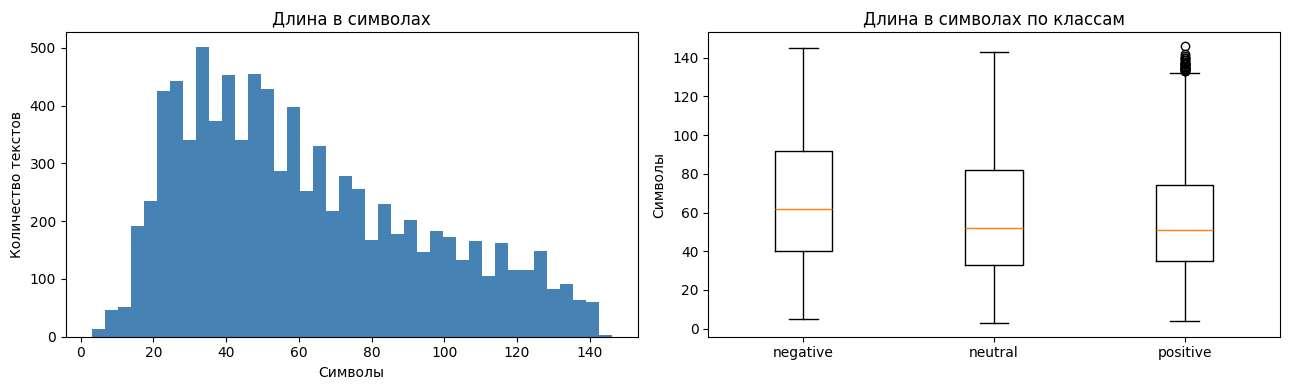

In [4]:
lengths = text_lengths(df)
display(lengths.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(2))
display(length_stats_by_class(df))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(lengths["chars"], bins=40, color="steelblue")
axes[0].set_title("Длина в символах")
axes[0].set_xlabel("Символы")
axes[0].set_ylabel("Количество текстов")

class_labels = sorted(df["label"].unique())
groups = [lengths.loc[df["label"] == label, "chars"].to_numpy() for label in class_labels]
axes[1].boxplot(groups)
axes[1].set_xticks(range(1, len(class_labels) + 1), class_labels)
axes[1].set_title("Длина в символах по классам")
axes[1].set_ylabel("Символы")

plt.tight_layout()
plt.show()

## 4. Примеры текстов из разных классов

In [5]:
display(show_examples(df, per_class=3))

,label,text
0,negative,Максимально допустимая продолжительность видео...
1,negative,опять ошибки да ок понятно тупица м
2,negative,@chern_ov Мне самой кажется эстетичным носы с ...
3,neutral,"Правильно пишется ""Конституции"""
4,neutral,@shkolar92 Так я ж не парней с видео имел ввид...
5,neutral,@ybudyan @SkunkAngry @Alex_zhzhet Квартира в н...
6,positive,хорошо мой павелитель 🙏🏻 https://t.co/pNYA8ucoYw
7,positive,@JoomOfficialRu вроде смешно https://t.co/Oo3u...
8,positive,Ничего необычного) 😂 https://t.co/mYrxsYTtmX


## 5. Проверка стратифицированного сплита

In [6]:
train_df, test_df = split_data(df)
print(f"train={len(train_df)}, test={len(test_df)}")
display(pd.DataFrame({"train": class_distribution(train_df), "test": class_distribution(test_df)}))

train=6631, test=2211


,train,test
label,,
negative,1978,660
neutral,3205,1068
positive,1448,483


## Первые наблюдения

- Датасет: 8842 твита, колонки `text` и `label`, три класса тональности. Пропусков, пустых строк и дубликатов нет.
- Диспропорция заметная: `neutral` 48.3%, `negative` 29.8%, `positive` 21.8%. Одна accuracy будет обманчивой, нужна F1-macro и стратификация.
- Тексты короткие: медиана 55 символов / 8 слов, 95% текстов короче 125 символов / 19 слов, максимум 146 символов. У `negative` медиана длиннее (62), чем у `neutral`/`positive` (52/51).
- Встречаются `@mentions` (~57% текстов), `t.co/` ссылки (~21%), эмодзи и переводы строк — на этапе предобработки их нужно чистить.
- Разметка тональности субъективная (в статье авторов указано умеренное согласие аннотаторов), поэтому стоит ожидать шум и внимательно смотреть на ошибки модели.
- Стратифицированный сплит выполняется: train 6631, test 2211, доли классов сохраняются.